# Machine Learning – Class Assignment
## Predicting Loan Default using a Decision Tree Classifier

**Name:** Manya Ruhela  |  **Class:** AI&ML-D  |  **Reg. No.:** RA2411026030193  
**Topic:** Supervised Learning – Classification

## Step 1: Import libraries and load the data

**Theory.** This is a *supervised classification* problem: every past customer comes with a label (`loan_default` = Yes/No), and the model learns the pattern linking the customer's features to that label so it can predict the label for new applicants. The first job in any such project is to check the data's size, column types and a few rows, because everything that follows (cleaning, encoding, choice of model) depends on what kind of columns we have.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

# Put loan_default.csv in the same folder as this notebook (or upload it in Colab)
df = pd.read_csv("loan_default.csv")

print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (1012, 18)

<class 'pandas.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1012 non-null   str    
 1   age                1012 non-null   int64  
 2   income             1012 non-null   float64
 3   loan_amount        1012 non-null   float64
 4   credit_score       1012 non-null   float64
 5   employment_years   1012 non-null   float64
 6   debt_to_income     1012 non-null   float64
 7   existing_loans     1012 non-null   int64  
 8   dependents         1012 non-null   int64  
 9   bank_balance       1012 non-null   float64
 10  interest_rate      1012 non-null   float64
 11  employment_type    1012 non-null   str    
 12  marital_status     1012 non-null   str    
 13  education          951 non-null    str    
 14  loan_purpose       1012 non-null   str    
 15  city_tier          1012 non-null   str    
 16  

In [2]:
df.head(10)

,customer_id,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,employment_type,marital_status,education,loan_purpose,city_tier,previous_defaults,loan_default
0,CUST00084,59,52055.0,67855.0,589.0,8.1,0.436,0,4,1841.31,10.75,Contract,Married,High School,Business,Tier 3,2,No
1,CUST00543,58,48605.0,187963.0,641.0,20.4,0.030,0,1,0.00,11.67,Salaried,Single,Graduate,Education,Tier 1,0,No
2,CUST00718,29,54590.0,244551.0,726.0,0.8,0.484,0,0,794.75,8.13,Contract,Married,High School,Personal,Tier 1,1,No
3,CUST00240,56,18951.0,561210.0,726.0,27.0,0.043,0,1,17515.85,8.63,Salaried,Single,High School,Education,Tier 1,0,No
4,CUST00649,37,76183.0,187744.0,658.0,10.1,0.412,1,3,10617.61,8.47,Salaried,Married,Undergraduate,Education,Tier 1,1,No
5,CUST00363,51,43421.0,203423.0,591.0,10.0,0.488,1,0,6242.09,9.82,Salaried,Single,Postgraduate,Education,Tier 1,1,No
6,CUST00302,32,61240.0,219736.0,653.0,7.3,0.460,1,2,564.28,9.22,Contract,Divorced,NaN,Business,Tier 2,1,No
7,CUST00568,43,75088.0,208966.0,635.0,17.5,0.469,0,3,11137.85,9.96,Salaried,Divorced,Undergraduate,Business,Tier 1,1,No
8,CUST00086,43,62544.0,328632.0,640.0,8.0,0.369,0,0,16709.98,9.59,Contract,Married,Graduate,Education,Tier 2,0,No
9,CUST00600,38,54997.0,273677.0,656.0,10.4,0.372,2,3,8650.50,9.71,Salaried,Single,Graduate,Business,Tier 1,0,No


In [3]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
text_cols    = df.select_dtypes(exclude="number").columns.tolist()
print("Numeric columns (%d):" % len(numeric_cols), numeric_cols)
print()
print("Text columns (%d):" % len(text_cols), text_cols)

Numeric columns (11): ['age', 'income', 'loan_amount', 'credit_score', 'employment_years', 'debt_to_income', 'existing_loans', 'dependents', 'bank_balance', 'interest_rate', 'previous_defaults']

Text columns (7): ['customer_id', 'employment_type', 'marital_status', 'education', 'loan_purpose', 'city_tier', 'loan_default']


**Write down – Answer:**  
The dataset has **1012 rows and 18 columns**.

- **Numeric (11):** age, income, loan_amount, credit_score, employment_years, debt_to_income, existing_loans, dependents, bank_balance, interest_rate, previous_defaults.
- **Categorical (5 features):** employment_type, marital_status, education, loan_purpose, city_tier.
- **Target (1):** loan_default (Yes/No, stored as text).
- **Identifier (1):** customer_id, which only labels the customer and carries no information about default, so it is not used as a feature.

## Step 2: Understand the data

**Theory.** `describe()` shows each numeric column's mean, spread (std), minimum, quartiles and maximum, which helps spot impossible values and very different scales. `value_counts()` shows how often each category occurs. Checking the **target distribution** is especially important: when one class is far more common (*class imbalance*), a model can score high *accuracy* simply by predicting the majority class every time, while failing to find the minority class, which here is the defaulters we actually care about.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1012.0,42.669960,13.986137,-52.00,32.000,43.000,54.00000,64.000
income,1012.0,54157.542490,21295.031417,-74577.00,40859.000,53837.500,68032.75000,111578.000
loan_amount,1012.0,246006.705534,116654.104628,20000.00,169464.500,242872.000,324349.50000,667635.000
credit_score,1012.0,651.821146,79.549937,411.00,596.750,651.500,705.00000,900.000
employment_years,1012.0,9.994763,7.718507,0.00,3.875,7.900,14.52500,33.600
debt_to_income,1012.0,0.368216,0.154261,0.02,0.263,0.371,0.47525,0.895
existing_loans,1012.0,0.996047,0.979505,0.00,0.000,1.000,2.00000,4.000
dependents,1012.0,1.936759,1.390213,0.00,1.000,2.000,3.00000,4.000
bank_balance,1012.0,8107.384951,6095.294697,0.00,3086.785,7747.690,12158.52250,34342.240
interest_rate,1012.0,9.325702,1.424837,6.00,8.370,9.270,10.25250,14.880


In [5]:
categorical_columns = ["employment_type", "marital_status", "education", "loan_purpose", "city_tier", "loan_default"]
for col in categorical_columns:
    print(df[col].value_counts(dropna=False))
    print()

employment_type
Salaried         463
Self-employed    220
Business         186
Contract         143
Name: count, dtype: int64

marital_status
Married     517
Single      409
Divorced     86
Name: count, dtype: int64

education
Undergraduate    377
Graduate         276
High School      183
Postgraduate     115
NaN               61
Name: count, dtype: int64

loan_purpose
Home         340
Personal     270
Business     247
Education    155
Name: count, dtype: int64

city_tier
Tier 1    416
Tier 2    350
Tier 3    246
Name: count, dtype: int64

loan_default
No     825
Yes    187
Name: count, dtype: int64



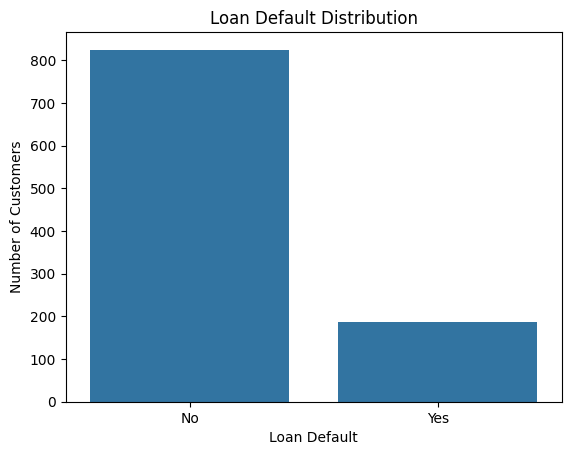

loan_default
No     0.815
Yes    0.185
Name: proportion, dtype: float64


In [6]:
sns.countplot(data=df, x="loan_default")
plt.title("Loan Default Distribution")
plt.xlabel("Loan Default")
plt.ylabel("Number of Customers")
plt.show()

print(df["loan_default"].value_counts(normalize=True).round(3))

**Write down – Answer:**  
The target is **not balanced**: 825 customers repaid (No, about 81.5%) and only 187 defaulted (Yes, about 18.5%), so there are roughly 4.4 times more repayers.

**Why it matters:**
- A model that always says "No default" would already be about 81–82% accurate while catching **zero** defaulters, so accuracy alone is misleading (the *accuracy paradox*).
- The model sees far fewer defaulter examples, so it tends to favour the majority class and miss defaulters.
- For this reason we also use recall, F1 and ROC-AUC, and use `stratify=y` when splitting the data.

## Step 3: Clean the data

**Theory.** Real data is rarely clean, and models cannot learn properly from errors.
- **Missing values:** most scikit-learn models cannot accept NaN. For a *categorical* column we can fill with the most frequent value (mode) or with a separate label such as `"Unknown"`. For a *numeric* column the **median** is preferred over the mean because it is not pulled by outliers.
- **Duplicate rows:** repeated records over-weight some customers and can leak the same row into both training and test sets, which makes test scores look better than they really are.
- **Impossible values:** a negative age or income is a data-entry error, not real information.

In [7]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print("Negative / zero ages:", (df["age"] <= 0).sum())
print("Negative incomes:", (df["income"] < 0).sum())
print("Negative loan amounts:", (df["loan_amount"] < 0).sum())

Missing values per column:
customer_id           0
age                   0
income                0
loan_amount           0
credit_score          0
employment_years      0
debt_to_income        0
existing_loans        0
dependents            0
bank_balance          0
interest_rate         0
employment_type       0
marital_status        0
education            61
loan_purpose          0
city_tier             0
previous_defaults     0
loan_default          0
dtype: int64



Duplicate rows: 11
Negative / zero ages: 5
Negative incomes: 5
Negative loan amounts: 0


In [8]:
print("Rows before cleaning:", len(df))

# 1. Remove duplicate rows
df = df.drop_duplicates().copy()

# 2. Fill missing education with a separate label
df["education"] = df["education"].fillna("Unknown")

# 3. Remove impossible values
df = df[(df["age"] > 0) & (df["income"] >= 0) & (df["loan_amount"] >= 0)].copy()

# 4. Safety net: numeric columns would be filled with the median (none are missing here)
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

print("Rows after cleaning:", len(df))
print("Missing values left:", int(df.isnull().sum().sum()))
print(df["loan_default"].value_counts().to_dict())

Rows before cleaning: 1012
Rows after cleaning: 991
Missing values left: 0
{'No': 812, 'Yes': 179}


**Write down – Answer:**  
- **Missing values:** only `education` had missing values (**61**). I replaced them with the label **"Unknown"**.
- **Why:** education is categorical, so a median is not possible. Using "Unknown" keeps all 61 customers and does not invent a qualification we do not know. The mode (Undergraduate) would have guessed a value for them, and missing education may itself carry some information, so I kept it as its own category.
- **Duplicates:** 11 duplicate rows were dropped, so the same customer is not counted twice or split across the train and test sets.
- **Impossible values:** 5 negative ages and 5 negative incomes were found and those 10 rows were removed. They cannot be corrected because the true value is unknown.
- After cleaning, **991 rows** remain (812 No, 179 Yes).

## Step 4: Explore the data visually

**Theory.** Visual exploration shows which features separate the two classes *before* modelling.
- A **boxplot** compares the distribution (median, spread, outliers) of a feature for defaulters and non-defaulters. If the two boxes sit at different heights, the feature is informative.
- The **default rate** of a category (the mean of the 0/1 target) shows whether some groups are riskier.
- A **correlation heatmap** shows the linear relationship (−1 to +1) between numeric columns. The *last row/column* (correlation with default) shows which features are linked to the target. Two features that are strongly correlated with *each other* (multicollinearity) carry overlapping information.

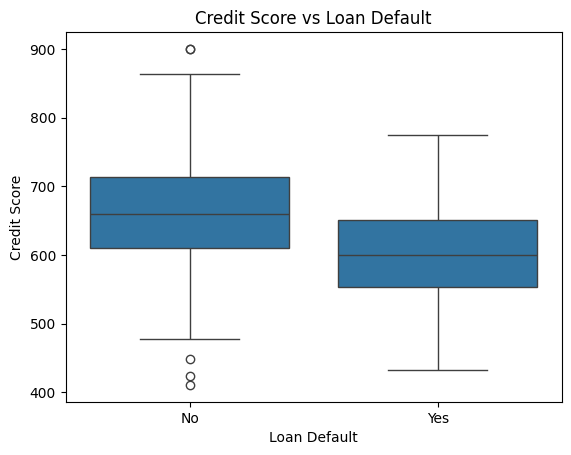

In [9]:
sns.boxplot(data=df, x="loan_default", y="credit_score")
plt.title("Credit Score vs Loan Default")
plt.xlabel("Loan Default")
plt.ylabel("Credit Score")
plt.show()

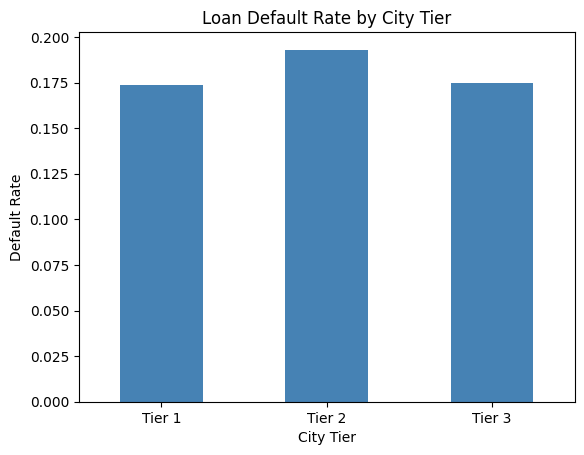

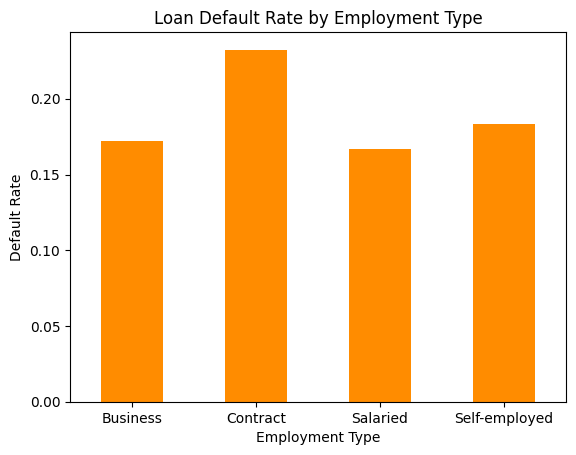

{'Tier 1': 0.174, 'Tier 2': 0.193, 'Tier 3': 0.175}
{'Business': 0.172, 'Contract': 0.232, 'Salaried': 0.167, 'Self-employed': 0.183}


In [10]:
df["default_numeric"] = df["loan_default"].map({"Yes": 1, "No": 0})

df.groupby("city_tier")["default_numeric"].mean().plot(kind="bar", color="steelblue")
plt.title("Loan Default Rate by City Tier")
plt.xlabel("City Tier"); plt.ylabel("Default Rate"); plt.xticks(rotation=0)
plt.show()

df.groupby("employment_type")["default_numeric"].mean().plot(kind="bar", color="darkorange")
plt.title("Loan Default Rate by Employment Type")
plt.xlabel("Employment Type"); plt.ylabel("Default Rate"); plt.xticks(rotation=0)
plt.show()

print(df.groupby("city_tier")["default_numeric"].mean().round(3).to_dict())
print(df.groupby("employment_type")["default_numeric"].mean().round(3).to_dict())

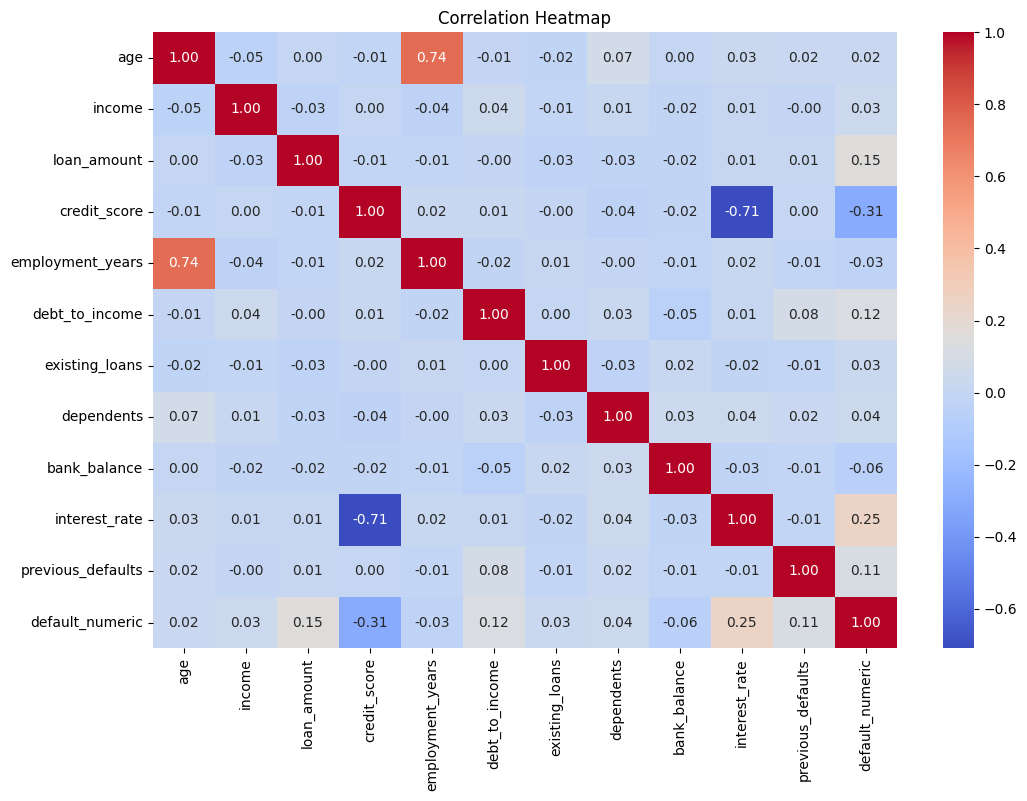

Correlation of each numeric feature with default:
credit_score        -0.305540
bank_balance        -0.056982
employment_years    -0.030939
age                  0.018501
existing_loans       0.026951
income               0.032113
dependents           0.038434
previous_defaults    0.107413
debt_to_income       0.118845
loan_amount          0.152059
interest_rate        0.246881
Name: default_numeric, dtype: float64


In [11]:
plt.figure(figsize=(12, 8))
numeric_data = df.select_dtypes(include="number")
sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

print("Correlation of each numeric feature with default:")
print(numeric_data.corr()["default_numeric"].drop("default_numeric").sort_values())

**Write down – Answer:**  
The two features that separate defaulters from non-defaulters best are:

1. **credit_score** – correlation with default **−0.31** (the strongest). Defaulters have a clearly lower median score (about 600 vs 660 for repayers). A lower score means higher risk.
2. **interest_rate** – correlation **+0.25** (second strongest). Defaulters carry higher rates (median about 10.0% vs 9.2%), which makes sense because lenders charge risky customers more.

Other features are weaker: loan_amount (+0.15), debt_to_income (+0.12) and previous_defaults (+0.11). City tier and employment type show only small differences in default rate (about 17–19% for most groups, with Contract workers highest at about 23%), so they are not strong separators. Note that interest_rate and credit_score are themselves strongly related (correlation −0.71), so they carry overlapping information.

## Step 5: Prepare the data for modelling

**Theory.** scikit-learn's Decision Tree works by repeatedly asking numeric questions of the form *"is feature ≤ threshold?"*. A word like "Salaried" cannot be compared with a threshold, so text must be converted to numbers.
- **One-hot encoding** (`pd.get_dummies`) creates one 0/1 column per category. It is preferred over simply numbering the categories (1, 2, 3…), because numbering would tell the model that, for example, Tier 3 is "bigger" than Tier 1, which is false.
- **drop_first=True** removes one dummy column per feature. The dropped category is implied when all other dummies are 0, so keeping it would be redundant (the *dummy variable trap*).
- The **target** is converted to 1 (default) and 0 (repaid), and **customer_id** is dropped because a unique code has no predictive meaning and could cause the model to memorise individuals.

In [12]:
df = df.drop(columns=["customer_id", "default_numeric"])
df["loan_default"] = df["loan_default"].map({"Yes": 1, "No": 0})
df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop("loan_default", axis=1)
y = df["loan_default"]

print("Feature matrix shape:", X.shape)
print("Columns:", list(X.columns))
X.head()

Feature matrix shape: (991, 25)
Columns: ['age', 'income', 'loan_amount', 'credit_score', 'employment_years', 'debt_to_income', 'existing_loans', 'dependents', 'bank_balance', 'interest_rate', 'previous_defaults', 'employment_type_Contract', 'employment_type_Salaried', 'employment_type_Self-employed', 'marital_status_Married', 'marital_status_Single', 'education_High School', 'education_Postgraduate', 'education_Undergraduate', 'education_Unknown', 'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal', 'city_tier_Tier 2', 'city_tier_Tier 3']


,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,...,marital_status_Single,education_High School,education_Postgraduate,education_Undergraduate,education_Unknown,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,city_tier_Tier 2,city_tier_Tier 3
0,59,52055.0,67855.0,589.0,8.1,0.436,0,4,1841.31,10.75,...,0,1,0,0,0,0,0,0,0,1
1,58,48605.0,187963.0,641.0,20.4,0.030,0,1,0.00,11.67,...,1,0,0,0,0,1,0,0,0,0
2,29,54590.0,244551.0,726.0,0.8,0.484,0,0,794.75,8.13,...,0,1,0,0,0,0,0,1,0,0
3,56,18951.0,561210.0,726.0,27.0,0.043,0,1,17515.85,8.63,...,1,1,0,0,0,1,0,0,0,0
4,37,76183.0,187744.0,658.0,10.1,0.412,1,3,10617.61,8.47,...,0,0,0,1,0,1,0,0,0,0


**Write down – Answer:**  
A scikit-learn Decision Tree can only split on **numbers**, using conditions like "credit_score ≤ 609.5". It has no way to calculate impurity or choose a threshold for text such as "Salaried" or "Tier 2", and the underlying arrays must be numeric. So text columns must be converted first, here with one-hot encoding. This gives 25 numeric feature columns.

## Step 6: Split into training and test sets

**Theory.** A model must be judged on data it has **never seen**. We therefore split the data: 80% to *train* (learn the patterns) and 20% to *test* (final exam). `stratify=y` keeps the same proportion of defaulters in both parts (about 18%), which matters because defaulters are rare, and `random_state=42` makes the split repeatable.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training set:", X_train.shape, "| default rate: %.3f" % y_train.mean())
print("Test set    :", X_test.shape, "| default rate: %.3f" % y_test.mean())

Training set: (792, 25) | default rate: 0.181
Test set    : (199, 25) | default rate: 0.181


**Write down – Answer:**  
The test set stands in for **future, unseen customers**. If we trained on it, the model could simply memorise those rows and the score would look excellent without telling us how it performs on new applicants (this is called *data leakage*). Keeping it aside gives an honest estimate of **generalisation**. Here the data was split into 792 training rows and 199 test rows, with the default rate kept at about 18% in both.

## Step 7: Train a Decision Tree

**Theory.** A Decision Tree learns a flowchart of yes/no questions. At every node it picks the feature and threshold that best separate the classes, measured by **impurity** (Gini by default, a measure of how mixed the classes are). With default settings it keeps splitting until every leaf is *pure*, which lets it fit the training data perfectly, including its noise. This is **overfitting**: excellent training accuracy but poorer accuracy on new data.

In [14]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

y_train_pred = dt.predict(X_train)
y_test_pred  = dt.predict(X_test)

print("Training accuracy: %.4f" % dt.score(X_train, y_train))
print("Test accuracy    : %.4f" % dt.score(X_test, y_test))
print("Tree depth:", dt.get_depth(), "| leaves:", dt.get_n_leaves())

Training accuracy: 1.0000
Test accuracy    : 0.7387
Tree depth: 14 | leaves: 121


**Write down – Answer:**  
Yes, there is a **big gap**: training accuracy is **100%** while test accuracy is only about **73.9%**, a gap of about 26 percentage points. This is a clear sign of **overfitting**. The unrestricted tree grew very deep (depth 14, 121 leaves) and memorised the training customers (including their noise) instead of learning general rules, so it does not carry over to unseen customers.

## Step 8: Evaluate the model properly

**Theory.**
- **Confusion matrix:** TN (repayer correctly predicted), FP (repayer wrongly flagged as defaulter), FN (defaulter wrongly passed as safe), TP (defaulter correctly caught).
- **Precision** = TP / (TP + FP): of those predicted to default, how many really did.
- **Recall** = TP / (TP + FN): of all real defaulters, how many we caught.
- **F1-score** = harmonic mean of precision and recall; it is low if either is low.
- **ROC-AUC:** the probability that the model gives a randomly chosen defaulter a higher risk score than a randomly chosen repayer. 0.5 means random guessing and 1.0 is perfect. It does not depend on the 0.5 cut-off and is useful for imbalanced data.

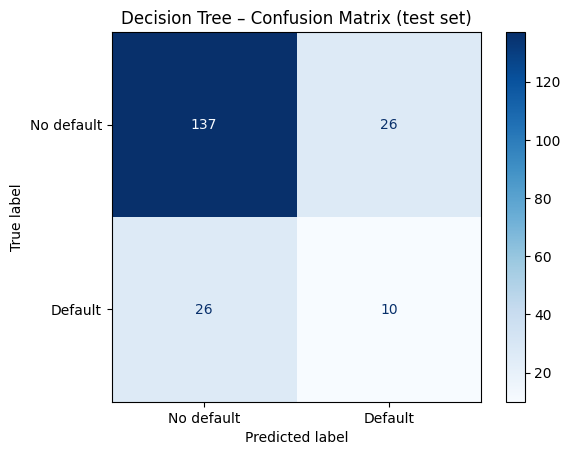

              precision    recall  f1-score   support

  No default       0.84      0.84      0.84       163
     Default       0.28      0.28      0.28        36

    accuracy                           0.74       199
   macro avg       0.56      0.56      0.56       199
weighted avg       0.74      0.74      0.74       199

ROC-AUC: 0.559


In [15]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score)

cm = confusion_matrix(y_test, y_test_pred)
ConfusionMatrixDisplay(cm, display_labels=["No default", "Default"]).plot(cmap="Blues", values_format="d")
plt.title("Decision Tree – Confusion Matrix (test set)")
plt.show()

print(classification_report(y_test, y_test_pred, target_names=["No default", "Default"]))

auc_dt = roc_auc_score(y_test, dt.predict_proba(X_test)[:, 1])
print("ROC-AUC:", round(auc_dt, 3))

**Write down – Answer:**  
**Approving a loan that defaults is worse.** The bank can lose the whole unpaid principal, whereas rejecting a good customer only loses the interest profit from one loan. In terms of the confusion matrix, a False Negative (a defaulter passed as safe) costs more than a False Positive.

This makes **recall for the default class** the most important metric, since it measures how many real defaulters we catch (with precision and ROC-AUC as supporting checks). Overall accuracy is not enough because of the class imbalance.

**Result:** the untuned tree caught only 10 of the 36 defaulters in the test set (**recall = 27.8%**) and its ROC-AUC is only **0.559**, barely better than random guessing (0.5). So the model is poor at detecting defaulters.

## Step 9: Control overfitting by tuning

**Theory.** *Hyperparameters* are settings we choose before training that control how complex the model can become:
- **max_depth** – how many questions in a row the tree may ask. Small depth gives a simple tree (may *underfit*); large depth gives a complex tree (may *overfit*). This is the **bias–variance trade-off**.
- **min_samples_leaf** – the minimum customers in a leaf; larger values stop the tree from making rules for just a few people.
- **criterion** – the impurity measure: *gini* or *entropy* (information gain).

**GridSearchCV** tries every combination and scores each with **5-fold cross-validation** (the training set is split into 5 parts; the model trains on 4 and validates on 1, rotating 5 times, and the scores are averaged). This chooses settings using the training data only, so the test set stays untouched.

In [16]:
rows = []
for depth in [3, 5, 7, 10]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    rows.append([depth, m.score(X_train, y_train), m.score(X_test, y_test)])

depth_table = pd.DataFrame(rows, columns=["max_depth", "Train accuracy", "Test accuracy"]).round(4)
depth_table["Gap"] = (depth_table["Train accuracy"] - depth_table["Test accuracy"]).round(4)
depth_table

,max_depth,Train accuracy,Test accuracy,Gap
0,3,0.8359,0.8141,0.0218
1,5,0.8737,0.8342,0.0395
2,7,0.9167,0.8090,0.1077
3,10,0.9773,0.7437,0.2336


In [17]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import recall_score, f1_score, accuracy_score

parameters = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_leaf": [1, 5, 10, 20],
    "criterion": ["gini", "entropy"],
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), parameters, cv=5)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_

print("Best parameters :", grid.best_params_)
print("Best CV accuracy: %.4f" % grid.best_score_)
print()
print("Tuned tree – train accuracy: %.4f" % best_model.score(X_train, y_train))
print("Tuned tree – test accuracy : %.4f" % best_model.score(X_test, y_test))

tuned_pred = best_model.predict(X_test)
print("Tuned tree – test recall   : %.4f" % recall_score(y_test, tuned_pred))
print("Tuned tree – test ROC-AUC  : %.4f" % roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1]))

Best parameters : {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 5}
Best CV accuracy: 0.8194

Tuned tree – train accuracy: 0.8321
Tuned tree – test accuracy : 0.8040
Tuned tree – test recall   : 0.1667
Tuned tree – test ROC-AUC  : 0.6360


**Write down – Answer:**  
- **Best max_depth in the manual test:** **max_depth = 5** gave the highest test accuracy (**83.42%**). Depth 3 gave 81.41%, depth 7 gave 80.90%, and depth 10 fell to 74.37%, nearly the same as the untuned tree. Training accuracy keeps rising with depth (83.6% to 97.7%) while test accuracy peaks and then falls, which is the classic overfitting pattern.
- **Caution:** depth 5 was picked by looking at the test set, so that 83.42% is slightly optimistic. GridSearchCV is the fairer method because it chooses using cross-validation on the training data only.
- **GridSearchCV result:** best settings were **criterion = entropy, max_depth = 3, min_samples_leaf = 5** (CV accuracy about 81.9%). On the test set this gives **80.40% accuracy**.
- **Compared with Step 7:** test accuracy rose from **73.87% to 80.40%**, ROC-AUC rose from 0.559 to 0.636, and the train–test gap shrank from about 26 points to about 3 points, so overfitting is much better controlled. Recall for defaulters, however, fell from 27.8% to 16.7%, because the simpler tree predicts "No default" more often. Tuning improved accuracy and stability, but did **not** solve the real problem of catching defaulters.

## Step 10: Compare with a baseline model

**Theory.** A *baseline* is a simple, well-understood model used as a yardstick. **Logistic Regression** is a linear model that estimates the probability of default as a weighted sum of the features passed through a sigmoid function; each weight shows the direction and strength of a feature, so it is easy to explain.
- It learns by gradient-based optimisation and is sensitive to feature size (e.g. income in tens of thousands vs. dependents of 0–4), so the features are scaled with **StandardScaler** (mean 0, standard deviation 1). The scaler is *fitted on the training data only* and then applied to the test data to avoid leakage.
- Decision Trees only compare a feature with thresholds, so scaling does not change them.
- Because only about 18% of customers default, a model that always predicts "No default" scores about 82% accuracy. Any model must be judged against that **majority-class baseline**.

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

log_model = LogisticRegression(max_iter=2000).fit(X_train_scaled, y_train)

models = ["Logistic Regression", "Decision Tree (untuned)", "Decision Tree (tuned)"]
preds  = [log_model.predict(X_test_scaled), dt.predict(X_test), best_model.predict(X_test)]
probs  = [log_model.predict_proba(X_test_scaled)[:, 1], dt.predict_proba(X_test)[:, 1], best_model.predict_proba(X_test)[:, 1]]

results = []
for name, p, pr in zip(models, preds, probs):
    results.append([name, accuracy_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p), roc_auc_score(y_test, pr)])

comparison = pd.DataFrame(results, columns=["Model", "Accuracy", "Recall", "F1 Score", "ROC-AUC"]).round(3)
print("Majority-class baseline (always predict 'No default') accuracy: %.3f" % (1 - y_test.mean()))
comparison

Majority-class baseline (always predict 'No default') accuracy: 0.819


,Model,Accuracy,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.829,0.167,0.261,0.716
1,Decision Tree (untuned),0.739,0.278,0.278,0.559
2,Decision Tree (tuned),0.804,0.167,0.235,0.636


**Write down – Answer:**  
**Recommendation: Logistic Regression**, with a caveat.

| Model | Accuracy | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Logistic Regression | 0.829 | 0.167 | 0.261 | **0.716** |
| Decision Tree (untuned) | 0.739 | 0.278 | 0.278 | 0.559 |
| Decision Tree (tuned) | 0.804 | 0.167 | 0.235 | 0.636 |

- It has the **best ROC-AUC (0.716)**, meaning it ranks risky customers above safe ones better than either tree, and the best accuracy (82.9%).
- It is **simple and explainable** (each feature has a weight), which matters when a bank must justify loan decisions.
- It overfits less than the untuned tree.

**Caveat:** the "always say No" baseline already scores 81.9%, so 82.9% accuracy is only a small improvement, and recall for defaulters is just 16.7%. The untuned tree has slightly higher recall (27.8%) only because it overfits and is a weaker model overall. **None of these models is ready for real use yet** (see Step 12 for a way to improve recall).

## Step 11: Interpret the model

**Theory.** A tree's **feature importance** is the total reduction in impurity (Gini/entropy) achieved by all the splits that use that feature, scaled so that all importances add up to 1. A feature never used in a split has importance 0. A path from the root to a leaf is a **decision rule** that a bank manager can read like plain English. Note that importance shows *association with the target, not cause and effect*.

Top 5 features:
credit_score      0.598
debt_to_income    0.194
loan_amount       0.164
income            0.043
age               0.000
dtype: float64


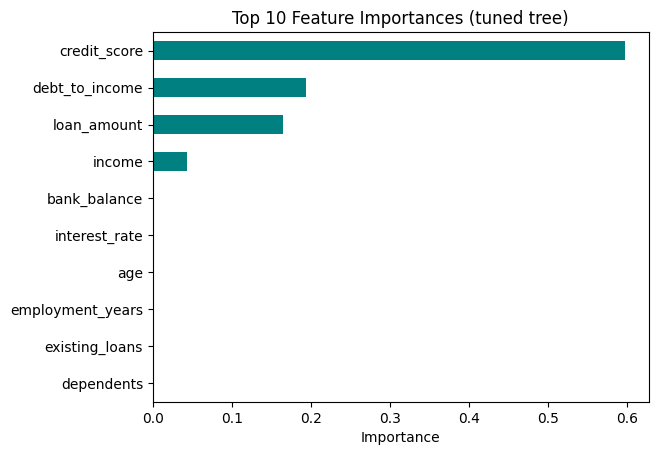

In [19]:
importance = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 5 features:")
print(importance.head(5).round(3))

importance.head(10).sort_values().plot(kind="barh", color="teal")
plt.title("Top 10 Feature Importances (tuned tree)")
plt.xlabel("Importance")
plt.show()

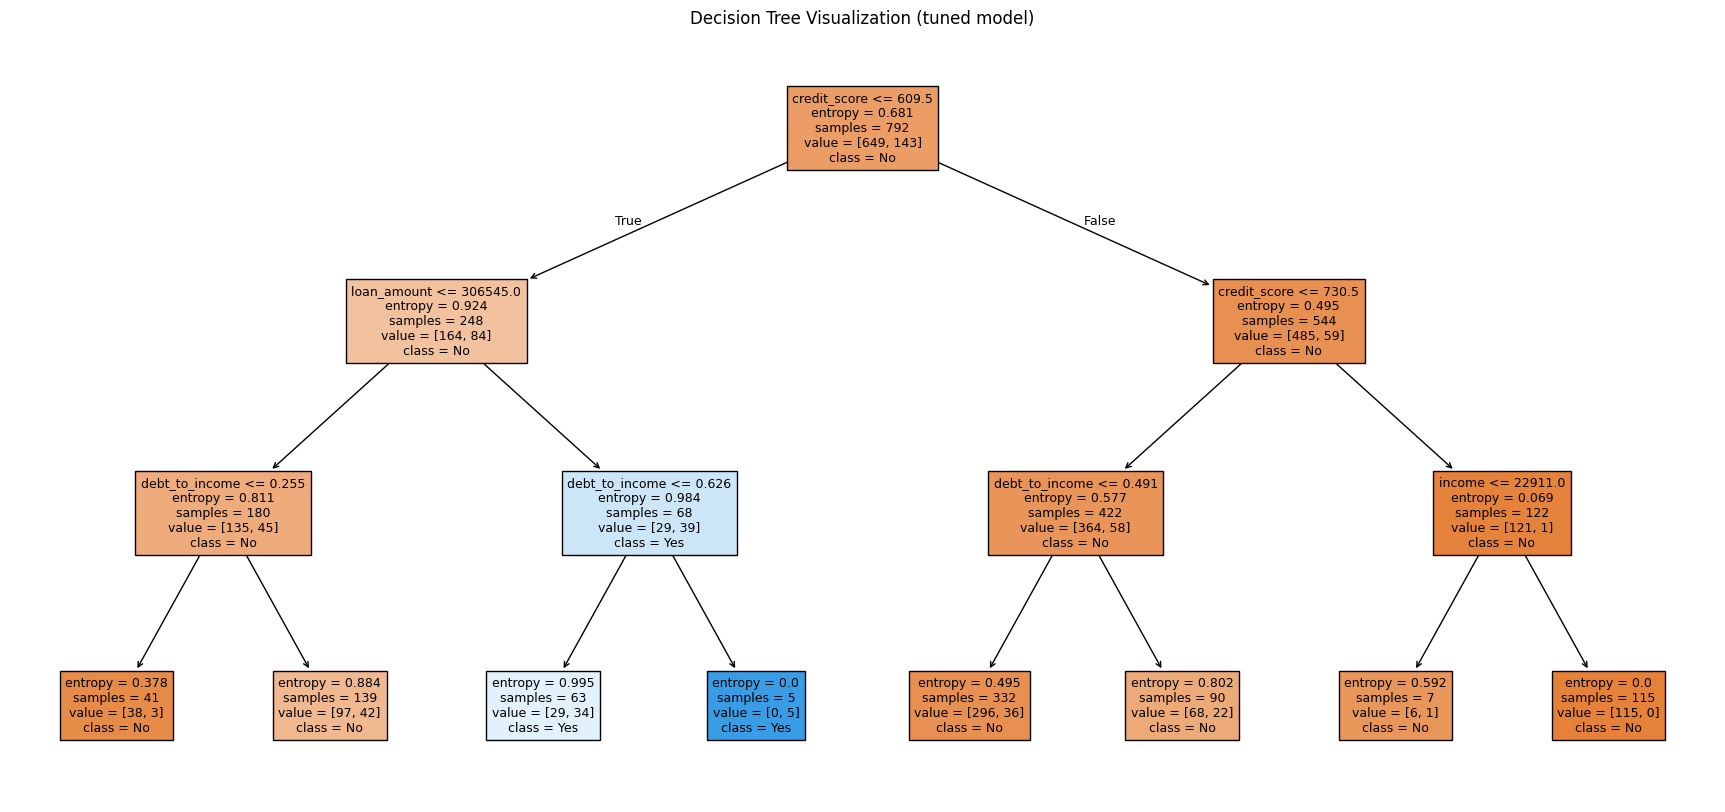

|--- credit_score <= 609.50
|   |--- loan_amount <= 306545.00
|   |   |--- debt_to_income <= 0.25
|   |   |   |--- class: 0
|   |   |--- debt_to_income >  0.25
|   |   |   |--- class: 0
|   |--- loan_amount >  306545.00
|   |   |--- debt_to_income <= 0.63
|   |   |   |--- class: 1
|   |   |--- debt_to_income >  0.63
|   |   |   |--- class: 1
|--- credit_score >  609.50
|   |--- credit_score <= 730.50
|   |   |--- debt_to_income <= 0.49
|   |   |   |--- class: 0
|   |   |--- debt_to_income >  0.49
|   |   |   |--- class: 0
|   |--- credit_score >  730.50
|   |   |--- income <= 22911.00
|   |   |   |--- class: 0
|   |   |--- income >  22911.00
|   |   |   |--- class: 0



In [20]:
from sklearn.tree import plot_tree, export_text

plt.figure(figsize=(22, 10))
plot_tree(best_model, feature_names=X.columns, class_names=["No", "Yes"], filled=True, max_depth=3, fontsize=9)
plt.title("Decision Tree Visualization (tuned model)")
plt.show()

print(export_text(best_model, feature_names=list(X.columns)))

**Write down – Answer:**  
**Top five features (tuned tree):**
1. credit_score – 0.598
2. debt_to_income – 0.194
3. loan_amount – 0.164
4. income – 0.043
5. age – 0.000 (the tree uses only four features; every other feature, including age, has zero importance, so the fifth place is a tie at zero)

**Do they match Step 4?** Partly.
- **credit_score matches:** it was the strongest feature in Step 4 (correlation −0.31) and is the most important feature here.
- **interest_rate does not appear** even though it was the second-best separator in Step 4. This is because it is strongly correlated with credit_score (−0.71), so once the tree splits on credit_score, interest_rate adds almost nothing new. This is normal for correlated features.
- debt_to_income and loan_amount had only weak individual correlations (+0.12, +0.15) in Step 4, but the tree finds them useful *in combination* with credit_score.

**Two decision rules in plain English:**
- **Rule 1 (risky):** If the customer's credit score is **609.5 or below** *and* the loan amount is **above 306,545**, the tree predicts **default**. In the training data, 39 of the 68 customers in this group (about 57%) defaulted, compared with about 18% overall.
- **Rule 2 (safe):** If the credit score is **above 730.5** *and* income is **above 22,911**, the tree predicts **repayment**. All 115 training customers in this group repaid.

In short: low credit score together with a big loan means high risk; a high credit score with a reasonable income means low risk.

## Extra: Random Forest and a class-weight improvement

**Theory.**
- **Random Forest** trains many decision trees on random samples of the rows and features (*bagging*) and averages their votes. Averaging reduces the variance of a single tree, so it overfits less and usually performs better.
- **class_weight="balanced"** tells a model to treat each defaulter as more important than each repayer (in proportion to how rare they are). It makes the model more willing to flag defaulters, which raises recall at the cost of more false alarms.

In [21]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_train, y_train)
log_bal = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train_scaled, y_train)

extra_models = ["Decision Tree (tuned)", "Random Forest", "Logistic Regression (balanced)"]
extra_preds  = [best_model.predict(X_test), rf.predict(X_test), log_bal.predict(X_test_scaled)]
extra_probs  = [best_model.predict_proba(X_test)[:, 1], rf.predict_proba(X_test)[:, 1], log_bal.predict_proba(X_test_scaled)[:, 1]]

rows = [[n, accuracy_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p), roc_auc_score(y_test, pr)]
        for n, p, pr in zip(extra_models, extra_preds, extra_probs)]
extra = pd.DataFrame(rows, columns=["Model", "Accuracy", "Recall", "F1 Score", "ROC-AUC"]).round(3)
extra

,Model,Accuracy,Recall,F1 Score,ROC-AUC
0,Decision Tree (tuned),0.804,0.167,0.235,0.636
1,Random Forest,0.854,0.194,0.326,0.689
2,Logistic Regression (balanced),0.693,0.611,0.419,0.720


In [22]:
print("Random Forest – top 5 features:")
print(pd.Series(rf.feature_importances_, index=X.columns).nlargest(5).round(3))

print()
print(classification_report(y_test, log_bal.predict(X_test_scaled), target_names=["No default", "Default"]))

Random Forest – top 5 features:
credit_score      0.145
loan_amount       0.113
interest_rate     0.113
debt_to_income    0.095
income            0.082
dtype: float64

              precision    recall  f1-score   support

  No default       0.89      0.71      0.79       163
     Default       0.32      0.61      0.42        36

    accuracy                           0.69       199
   macro avg       0.61      0.66      0.61       199
weighted avg       0.79      0.69      0.72       199



**Extra – Answer:**
- **Random Forest** beats the tuned tree on every measure: accuracy **85.4%** vs 80.4%, recall 19.4% vs 16.7%, F1 0.326 vs 0.235, ROC-AUC **0.689** vs 0.636. Its recall is still low, so it too misses most defaulters.
- **Logistic Regression with balanced class weights** raises recall for defaulters from 16.7% to about **61%** (22 of 36 caught) and F1 to 0.419, with ROC-AUC staying about 0.72. The price is lower accuracy (about 69%) because many good customers are now flagged. For a bank where missing a defaulter is the costlier mistake, this is often the better trade-off.
- Random Forest's top features are again credit_score, loan_amount, interest_rate, debt_to_income and income, which agrees with the earlier analysis.

## Step 12: Conclusion

**Summary for the bank manager.**

We built and tested models to predict which loan applicants may default, using 991 cleaned customer records, of which about 18% defaulted. A basic decision tree memorised the training data and fell from 100% to 74% accuracy on new customers, but tuning it brought test accuracy to about 80%, and Logistic Regression was the best overall model (82.9% accuracy, ROC-AUC 0.72). The models do well at **ranking** applicants by risk, and the clearest warning signs are a low credit score (below about 610), a large loan amount and a high debt-to-income ratio, while a score above about 730 is a safe sign. Their main **limitation** is that they catch only about 17–28% of real defaulters, so they are not yet safe to use alone, and the dataset is small with few defaulters. The **one thing I would do to improve it** is to give defaulters extra weight (class balancing), which lifted recall to about 61% in our test, and then confirm it with more data and a Random Forest.

**Write down – Answer:**
- **Does well:** ranks applicants by risk (ROC-AUC about 0.72 for Logistic Regression), and finds sensible, explainable risk factors (credit score, loan amount, debt-to-income).
- **Limitations:** low recall for defaulters (17–28% for the main models), small dataset (991 rows, only 179 defaulters), results from a single 80/20 split, and accuracy that looks good mainly because most customers repay.
- **One improvement:** correct the class imbalance with class weights (or resampling) so that more defaulters are caught, and collect more data; a Random Forest also gave better overall scores.